## Import Library

In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

os.environ["HF_HOME"] = "./hf_cache"

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import pipeline

## Import Dataset Latih (IndoNLU 11k)

In [3]:
url = "https://huggingface.co/datasets/indonlu/resolve/refs%2Fconvert%2Fparquet/smsa/train/0000.parquet"
df_train = pd.read_parquet(url)

label_map = {0: 'Positif', 1: 'Netral', 2: 'Negatif'}
df_train['label_name'] = df_train['label'].map(label_map)

print(f"Total Dataset: {df_train.shape[0]} baris.")
display(df_train.head())


Total Dataset: 11000 baris.


,text,label,label_name
0,warung ini dimiliki oleh pengusaha pabrik tahu...,0,Positif
1,mohon ulama lurus dan k212 mmbri hujjah partai...,1,Netral
2,lokasi strategis di jalan sumatera bandung . t...,0,Positif
3,betapa bahagia nya diri ini saat unboxing pake...,0,Positif
4,duh . jadi mahasiswa jangan sombong dong . kas...,2,Negatif


## Exploratory Data Analysis

C:\Users\tiant\AppData\Local\Temp\ipykernel_12976\439574195.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, x='label_name', palette='pastel')


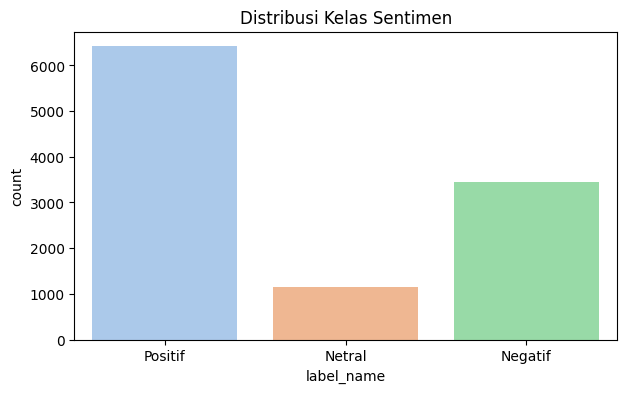

In [4]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df_train, x='label_name', palette='pastel')
plt.title('Distribusi Kelas Sentimen')
plt.show()


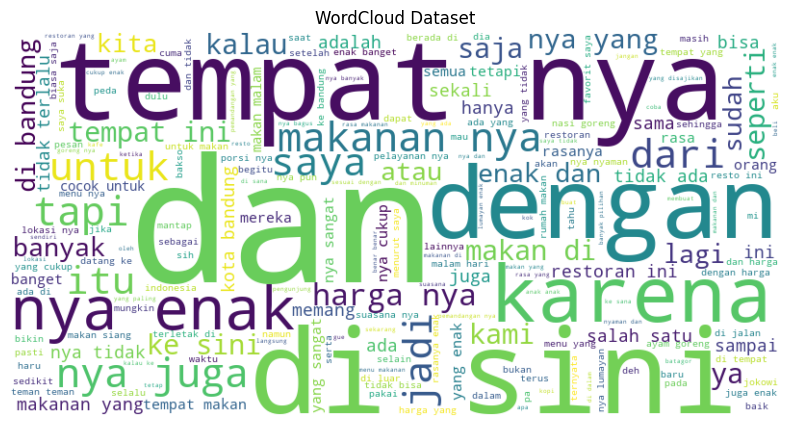

In [5]:
text_gabungan = " ".join(df_train['text'].astype(str))
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(text_gabungan)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud Dataset')
plt.show()


## Preprocessing

In [6]:
df_sample = df_train.sample(n=2000, random_state=42).copy()

factory_stemmer = StemmerFactory()
stemmer = factory_stemmer.create_stemmer()
factory_stopword = StopWordRemoverFactory()
stopword_remover = factory_stopword.create_stop_word_remover()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'\@\w+|\#', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    return text.strip()

def remove_stopwords_and_stem(text):
    text = stopword_remover.remove(text)
    return stemmer.stem(text)

df_sample['Teks Bersih'] = df_sample['text'].apply(clean_text)
df_sample['Teks Final'] = df_sample['Teks Bersih'].apply(remove_stopwords_and_stem)

print("Tabel Hasil Preprocessing Teks:")
df_preprocessing_result = df_sample[['text', 'Teks Bersih', 'Teks Final']].head(10)
display(df_preprocessing_result)


Tabel Hasil Preprocessing Teks:


,text,Teks Bersih,Teks Final
107,saya tadinya penasaran dengan tempat ini karen...,saya tadinya penasaran dengan tempat ini karen...,tadi penasaran tempat karena tempat nya banyak...
5484,kasus korupsi anies baswedan di pameran buku j...,kasus korupsi anies baswedan di pameran buku j...,kasus korupsi anies baswedan pamer buku jerman...
6998,"sebagai penggemar bakso tahu , kualitas terbai...",sebagai penggemar bakso tahu kualitas terbaik...,gemar bakso tahu kualitas baik dapat saboga se...
3984,meskipun jalan yang ditempuh cukup sulit dan h...,meskipun jalan yang ditempuh cukup sulit dan h...,meski jalan tempuh cukup sulit harus tanjak ba...
3111,restoran di kemang village momi toy . mahal da...,restoran di kemang village momi toy mahal dan...,restoran kemang village momi toy mahal tidak e...
4040,beberapa kali saya berkunjung ke resto rose fl...,beberapa kali saya berkunjung ke resto rose fl...,beberapa kali kunjung resto rose flower selalu...
3013,restoran ini terletak di jalan braga bandung ....,restoran ini terletak di jalan braga bandung ...,restoran letak jalan braga bandung cukup ramai...
6607,saya sudah kirim email complaint karena telepo...,saya sudah kirim email complaint karena telepo...,sudah kirim email complaint telepon masuk terus
4219,ikan bakar pak chi met waktu di btc dan sukaja...,ikan bakar pak chi met waktu di btc dan sukaja...,ikan bakar pak chi met waktu btc sukajadi rama...
8750,aku suka sekali membeli buku di gramedia,aku suka sekali membeli buku di gramedia,aku suka sekali beli buku gramedia


## Modelling 1: LSTM

In [7]:
max_words = 5000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(df_sample['Teks Final'])
sequences = tokenizer.texts_to_sequences(df_sample['Teks Final'])
X_pad = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

y = df_sample['label'].values
X_train, X_test, y_train, y_test = train_test_split(X_pad, y, test_size=0.2, random_state=42)

X_train_tensor = torch.tensor(X_train, dtype=torch.long)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_test_tensor = torch.tensor(X_test, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_data = torch.utils.data.TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)


In [8]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, output_dim)
        self.dropout = nn.Dropout(0.3)

    def forward(self, text):
        embedded = self.dropout(self.embedding(text))
        output, (hidden, cell) = self.lstm(embedded)
        hidden_concat = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        return self.fc(self.dropout(hidden_concat))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
model_lstm = SentimentLSTM(vocab_size=max_words, embed_dim=128, hidden_dim=64, output_dim=3).to(device)

optimizer = torch.optim.Adam(model_lstm.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

epochs = 3
for epoch in range(epochs):
    model_lstm.train()
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        predictions = model_lstm(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    print(f"Epoch: {epoch+1}/{epochs} | Loss: {epoch_loss/len(train_loader):.4f}")


cpu
Epoch: 1/3 | Loss: 0.9166
Epoch: 2/3 | Loss: 0.7701
Epoch: 3/3 | Loss: 0.6415


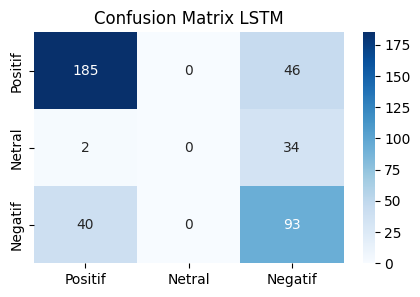

In [9]:
model_lstm.eval()
with torch.no_grad():
    preds = model_lstm(X_test_tensor.to(device))
    preds_classes = torch.argmax(preds, dim=1).cpu().numpy()

cm = confusion_matrix(y_test, preds_classes)
plt.figure(figsize=(5,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Positif', 'Netral', 'Negatif'], yticklabels=['Positif', 'Netral', 'Negatif'])
plt.title("Confusion Matrix LSTM")
plt.show()


## Modelling 2: Transformer

In [10]:
print("Memuat Model IndoBERT...")
transformer_pipeline = pipeline(
    "sentiment-analysis",
    model="w11wo/indonesian-roberta-base-sentiment-classifier"
)


Memuat Model IndoBERT...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

## Prediksi & Visualisasi Data YouTube (Offline CSV)

Berhasil memuat 6632 data komentar YouTube dari CSV.
Mulai memprediksi sentimen komentar...


,Keyword,Komentar,Sentimen AI
0,pemberitaan politik indonesia,"Jangan lihat siapa yg bicara, tapi lihatlah ap...",Negatif
1,pemberitaan politik indonesia,nungguin banget pak prabowo lengser seriusssss...,Negatif
2,pemberitaan politik indonesia,Semoga cepat terwujud doa bang noel,Positif
3,pemberitaan politik indonesia,semoga terjadi yaaaaa !!!!,Negatif
4,pemberitaan politik indonesia,Jika aktivis telah diangkat menduduki suatu ja...,Negatif
5,pemberitaan politik indonesia,Eksekusi saja 😂😂,Negatif
6,pemberitaan politik indonesia,Terdesak😅,Negatif
7,pemberitaan politik indonesia,Maling bacod mulu,Negatif
8,pemberitaan politik indonesia,Harus bersatu memang rakyat.,Negatif
9,pemberitaan politik indonesia,"udah koruptor omongan nya gak kena di pegang, ...",Negatif


C:\Users\tiant\AppData\Local\Temp\ipykernel_12976\999287008.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_youtube, x='Sentimen AI', palette='Set1', order=['Positif', 'Netral', 'Negatif'])


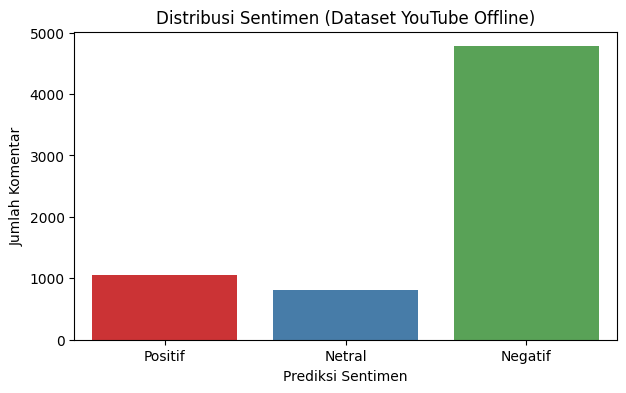

In [11]:
# Membaca data yang sebelumnya telah diekstrak ke dalam file CSV
if os.path.exists("youtube_dataset.csv"):
    df_youtube = pd.read_csv("youtube_dataset.csv")
    print(f"Berhasil memuat {df_youtube.shape[0]} data komentar YouTube dari CSV.")

    # Lakukan prediksi sentimen untuk setiap komentar menggunakan Transformer
    print("Mulai memprediksi sentimen komentar...")
    sentimen_ai = []
    for text in df_youtube['Komentar']:
        try:
            raw_label = transformer_pipeline(str(text), truncation=True, max_length=512)[0]['label'].lower()
            label_map_id = {'positive': 'Positif', 'negative': 'Negatif', 'neutral': 'Netral'}
            sent = label_map_id.get(raw_label, 'Netral')
        except Exception as e:
            sent = "Netral"
        sentimen_ai.append(sent)

    df_youtube['Sentimen AI'] = sentimen_ai

    display(df_youtube[['Keyword', 'Komentar', 'Sentimen AI']].head(10))

    # Visualisasi Diagram Batang
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df_youtube, x='Sentimen AI', palette='Set1', order=['Positif', 'Netral', 'Negatif'])
    plt.title('Distribusi Sentimen (Dataset YouTube Offline)')
    plt.ylabel('Jumlah Komentar')
    plt.xlabel('Prediksi Sentimen')
    plt.show()
else:
    print("File youtube_dataset.csv tidak ditemukan! Silakan jalankan script ekstraksi data terlebih dahulu.")


## Pengujian Interaktif (Simulasi Aplikasi)